Station pollution:
     station_name  avg_pm25  max_pm25  median_pm25  observations
       Karve Road 45.383351  893.4200    38.675000         10974
     Mhada Colony 43.459905  255.8650    35.155000         15927
           Alandi 42.034742  849.7500    31.430000          6165
             SPPU 35.073737  867.2550    27.762500         16124
Panchawati_Pashan 27.509375  199.2725    22.263333         10965

DBSCAN POLLUTION CLUSTERS
     station_name  avg_pm25  max_pm25  cluster hotspot_type
       Karve Road 45.383351  893.4200       -1     Isolated
     Mhada Colony 43.459905  255.8650       -1     Isolated
           Alandi 42.034742  849.7500       -1     Isolated
             SPPU 35.073737  867.2550       -1     Isolated
Panchawati_Pashan 27.509375  199.2725       -1     Isolated


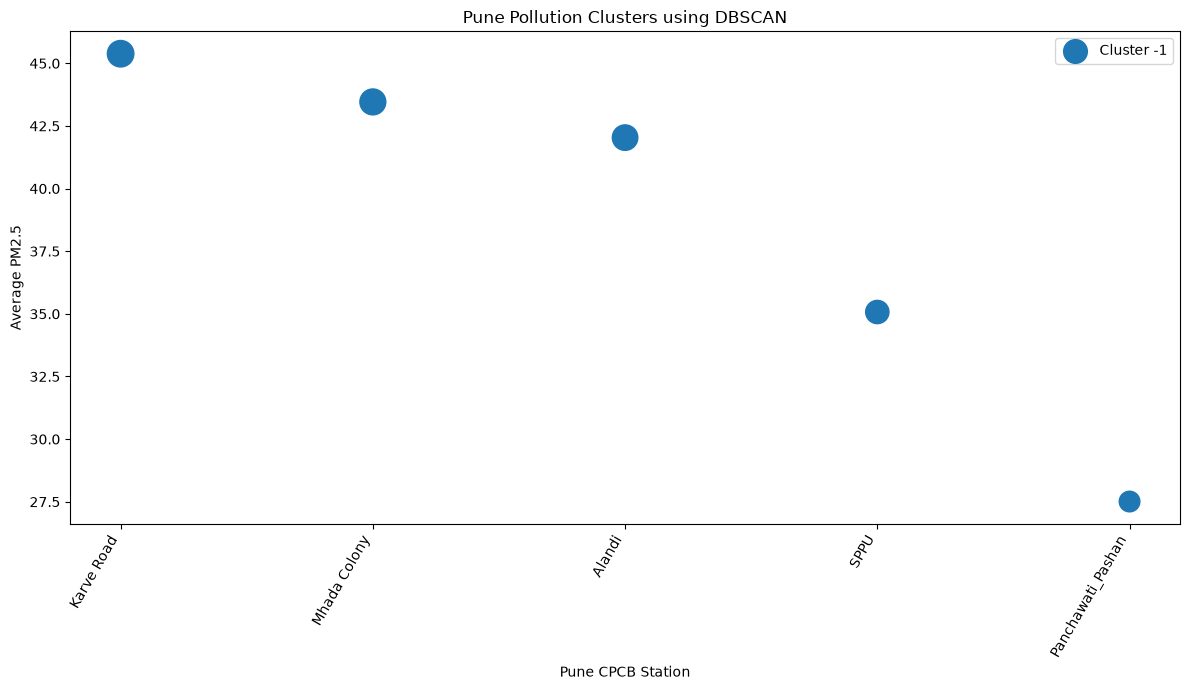


DBSCAN completed successfully.


In [2]:
# ============================================================
# DBSCAN POLLUTION CLUSTERING - ALL PUNE STATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(
    "../data/processed/pune_cpcb_cleaned_hourly.csv"
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df["pm25"] = pd.to_numeric(
    df["pm25"],
    errors="coerce"
)

df = df.dropna(
    subset=["pm25"]
)


# ------------------------------------------------------------
# 2. STATION-LEVEL POLLUTION
# ------------------------------------------------------------

station_data = (
    df.groupby("station_name")
      .agg(
          avg_pm25=("pm25", "mean"),
          max_pm25=("pm25", "max"),
          median_pm25=("pm25", "median"),
          observations=("pm25", "count")
      )
      .reset_index()
)


print("Station pollution:")
print(
    station_data.sort_values(
        "avg_pm25",
        ascending=False
    ).to_string(index=False)
)


# ------------------------------------------------------------
# 3. USE POLLUTION FEATURES
# ------------------------------------------------------------

X = station_data[
    [
        "avg_pm25",
        "max_pm25",
        "median_pm25"
    ]
]


# ------------------------------------------------------------
# 4. STANDARDIZE
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ------------------------------------------------------------
# 5. DBSCAN
# ------------------------------------------------------------

dbscan = DBSCAN(
    eps=1.0,
    min_samples=2
)

station_data["cluster"] = (
    dbscan.fit_predict(X_scaled)
)


# ------------------------------------------------------------
# 6. HOTSPOT CLASSIFICATION
# ------------------------------------------------------------

def hotspot(row):

    if row["cluster"] == -1:
        return "Isolated"

    if row["avg_pm25"] >= 90:
        return "High Pollution Hotspot"

    elif row["avg_pm25"] >= 60:
        return "Moderate Pollution Hotspot"

    else:
        return "Low Pollution Cluster"


station_data["hotspot_type"] = (
    station_data.apply(
        hotspot,
        axis=1
    )
)


# ------------------------------------------------------------
# 7. SORT BY POLLUTION
# ------------------------------------------------------------

station_data = station_data.sort_values(
    "avg_pm25",
    ascending=False
)


# ------------------------------------------------------------
# 8. DISPLAY
# ------------------------------------------------------------

print("\n======================================")
print("DBSCAN POLLUTION CLUSTERS")
print("======================================")

print(
    station_data[
        [
            "station_name",
            "avg_pm25",
            "max_pm25",
            "cluster",
            "hotspot_type"
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 9. SAVE
# ------------------------------------------------------------

station_data.to_csv(
    "../data/processed/dbscan_pollution_hotspots.csv",
    index=False
)


# ------------------------------------------------------------
# 10. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

for cluster in sorted(
    station_data["cluster"].unique()
):

    data = station_data[
        station_data["cluster"] == cluster
    ]

    plt.scatter(
        data["station_name"],
        data["avg_pm25"],
        s=data["avg_pm25"] * 8,
        label=f"Cluster {cluster}"
    )


plt.xticks(
    rotation=60,
    ha="right"
)

plt.xlabel("Pune CPCB Station")

plt.ylabel("Average PM2.5")

plt.title(
    "Pune Pollution Clusters using DBSCAN"
)

plt.legend()

plt.tight_layout()

plt.show()


print("\nDBSCAN completed successfully.")